# 04 误差分析：模型在哪里失效

四条切法（时段 / 星期 / 价格分位 / 波动率）+ 一个显著性检验。

In [1]:
# 自包含引导：从当前目录向上找到含 src/config.py 的仓库根，再挂到 sys.path
import sys, pathlib
p = pathlib.Path.cwd()
while not (p / "src" / "config.py").exists() and p != p.parent:
    p = p.parent
sys.path.insert(0, str(p / "src"))
print("仓库根:", p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 中文字体（macOS 用苹方），否则标题变方框
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

import data_io, features as F, split as S, models as M, evaluate as E

d = F.build_features(data_io.for_market(data_io.load_raw(), "DA"), h=1)
parts, spans = S.time_split(d)
tr, te = parts["train"], parts["test"]

Xtr, ytr = tr[F.FEATURES], tr["y"]
Xte, yte = te[F.FEATURES], te["y"]

rf = M.make_rf().fit(Xtr, ytr)
ridge = M.make_ridge().fit(Xtr, ytr)
res = E.add_residuals(te, rf.predict(Xte))
res_ridge = E.add_residuals(te, ridge.predict(Xte))
print("RF  测试集 MAE:", round(res["abs_err"].mean(), 2))
print("Ridge 测试集 MAE:", round(res_ridge["abs_err"].mean(), 2))

仓库根: /Users/xian/Desktop/electricity-price
[features] h=1 丢弃 193 行（lag96 热身 + 末尾 1 行），保留 36959
RF  测试集 MAE: 22.51
Ridge 测试集 MAE: 24.7


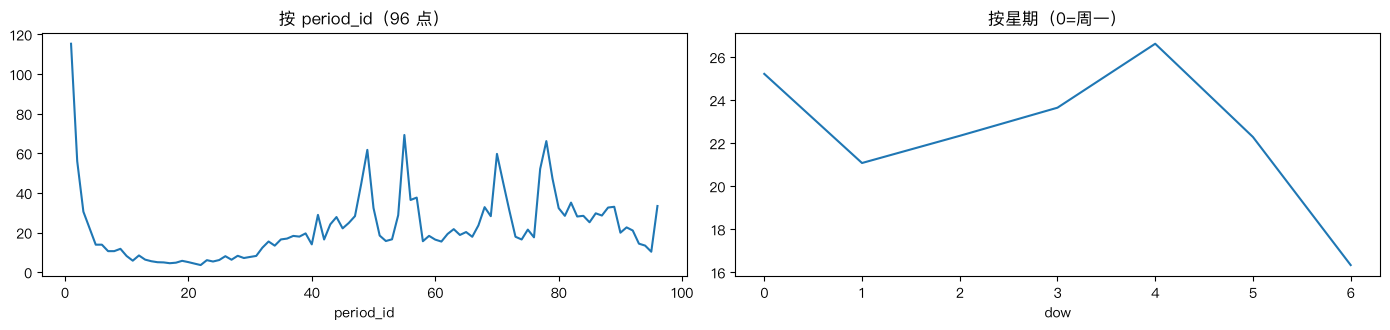

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
E.error_by_period(res).plot(ax=axes[0], title="按 period_id（96 点）")
E.error_by_dow(res).plot(ax=axes[1], title="按星期（0=周一）")
plt.tight_layout()

In [3]:
# 按真实价格十分位：看两端（负价 / 尖峰）是否最差
E.error_by_bucket(res)
# 按前 24h 波动率五分位：看"越乱越准不了"
E.error_by_vol(res)

,mean,count
roll_std_96,,
0,12.396835,1479
1,15.069706,1478
2,22.279195,1478
3,26.734521,1478
4,36.054423,1478


In [4]:
print("残差 lag1 自相关:", round(res["err"].autocorr(lag=1), 3))

mean_diff, ci = E.bootstrap_diff(res["abs_err"], res_ridge["abs_err"])
print(f"RF - Ridge 的 MAE 差 = {mean_diff:+.2f}, 95% 区间 = [{ci[0]:+.2f}, {ci[1]:+.2f}]")
print("区间不含 0 → 差异显著" if ci[0] * ci[1] > 0 else "区间含 0 → 差异在噪声范围内")

残差 lag1 自相关: 0.369
RF - Ridge 的 MAE 差 = -2.20, 95% 区间 = [-2.69, -1.71]
区间不含 0 → 差异显著


误差最大单日: 2025-06-23 该日 MAE = 80.19


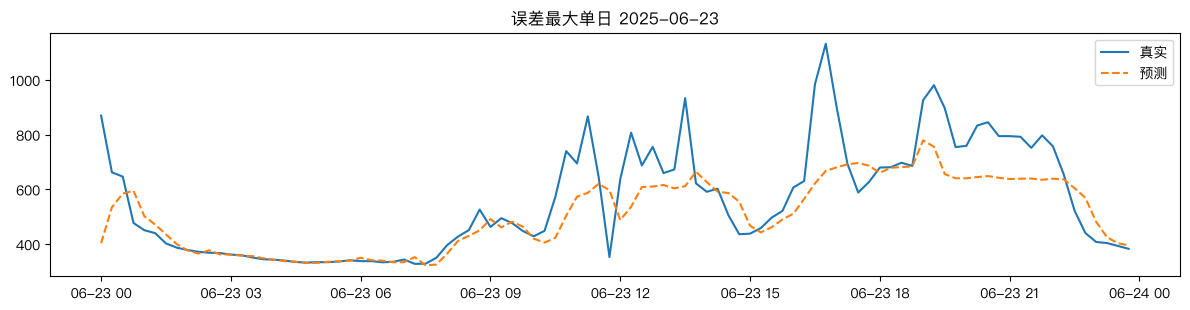

In [5]:
worst = res.groupby("trade_date")["abs_err"].mean().idxmax()
day = res[res["trade_date"] == worst].sort_values("delivery_time")
print("误差最大单日:", str(worst)[:10], "该日 MAE =", round(day["abs_err"].mean(), 2))

plt.figure(figsize=(12, 3.2))
plt.plot(day["delivery_time"], day["y"], label="真实")
plt.plot(day["delivery_time"], day["yhat"], ls="--", label="预测")
plt.title(f"误差最大单日 {str(worst)[:10]}")
plt.legend(); plt.tight_layout()